In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/Annathearmy/Zomato-Analysis/main/DATA/zomato_bengaluru_restaurants_data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.shape)
display(df.head())

Dataset loaded successfully!
(742, 11)


,UniqueID,Suburb,Restaurant Type,Online Order Facility,Dine-in Facility,Avg Approx Cost (For Two People),Avg Rating,Avg Votes,Restaurant Count,Latitude,Longitude
0,ZM1000,BTM,Buffet,No,No,808.333333,3.48000,138.500000,6,12.919468,77.615494
1,ZM1001,BTM,Buffet,No,Yes,1323.529412,4.25625,1934.235294,17,12.919468,77.615494
2,ZM1002,BTM,Buffet,Yes,No,737.500000,3.62500,1850.500000,4,12.919468,77.615494
3,ZM1003,BTM,Buffet,Yes,Yes,1250.000000,4.32500,1773.083333,12,12.919468,77.615494
4,ZM1004,BTM,Cafes,No,No,541.935484,3.85000,772.937500,32,12.919468,77.615494


In [13]:
# Understanding the dataset

print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical description:")
display(df.describe())

print("\nColumn names:")
print(df.columns)

print("\nDataset shape:")
print(df.shape)

First 5 rows:


,UniqueID,Suburb,Restaurant Type,Online Order Facility,Dine-in Facility,Avg Approx Cost (For Two People),Avg Rating,Avg Votes,Restaurant Count,Latitude,Longitude
0,ZM1000,BTM,Buffet,No,No,808.333333,3.48000,138.500000,6,12.919468,77.615494
1,ZM1001,BTM,Buffet,No,Yes,1323.529412,4.25625,1934.235294,17,12.919468,77.615494
2,ZM1002,BTM,Buffet,Yes,No,737.500000,3.62500,1850.500000,4,12.919468,77.615494
3,ZM1003,BTM,Buffet,Yes,Yes,1250.000000,4.32500,1773.083333,12,12.919468,77.615494
4,ZM1004,BTM,Cafes,No,No,541.935484,3.85000,772.937500,32,12.919468,77.615494



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 742 entries, 0 to 741
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   UniqueID                          742 non-null    object 
 1   Suburb                            742 non-null    object 
 2   Restaurant Type                   742 non-null    object 
 3   Online Order Facility             742 non-null    object 
 4   Dine-in Facility                  742 non-null    object 
 5   Avg Approx Cost (For Two People)  742 non-null    float64
 6   Avg Rating                        737 non-null    float64
 7   Avg Votes                         742 non-null    float64
 8   Restaurant Count                  742 non-null    int64  
 9   Latitude                          742 non-null    float64
 10  Longitude                         742 non-null    float64
dtypes: float64(5), int64(1), object(5)
memory usage: 

,Avg Approx Cost (For Two People),Avg Rating,Avg Votes,Restaurant Count,Latitude,Longitude
count,742.000000,737.000000,742.000000,742.000000,742.000000,742.000000
mean,955.078173,3.912605,743.674807,69.699461,12.947899,77.622104
std,444.671043,0.292505,726.092235,142.948817,0.044624,0.047422
min,150.000000,2.600000,0.000000,1.000000,12.821949,77.557671
25%,520.479452,3.666667,155.837529,5.000000,12.929118,77.580452
50%,963.250000,3.950000,528.280392,15.000000,12.961576,77.611343
75%,1299.134150,4.155172,1156.238636,53.000000,12.973336,77.643271
max,2200.000000,4.700000,4678.000000,1258.000000,13.028499,77.751038



Column names:
Index(['UniqueID', 'Suburb', 'Restaurant Type', 'Online Order Facility',
       'Dine-in Facility', 'Avg Approx Cost (For Two People)', 'Avg Rating',
       'Avg Votes', 'Restaurant Count', 'Latitude', 'Longitude'],
      dtype='object')

Dataset shape:
(742, 11)


In [14]:
# Checking missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
UniqueID                            0
Suburb                              0
Restaurant Type                     0
Online Order Facility               0
Dine-in Facility                    0
Avg Approx Cost (For Two People)    0
Avg Rating                          5
Avg Votes                           0
Restaurant Count                    0
Latitude                            0
Longitude                           0
dtype: int64

Total missing values:
5


In [15]:
# Data Transformation

# Drop unnecessary UniqueID column
df = df.drop(columns=["UniqueID"])

# Convert numeric columns into proper data types
numeric_columns = [
    "Avg Approx Cost (For Two People)",
    "Avg Rating",
    "Avg Votes",
    "Restaurant Count",
    "Latitude",
    "Longitude"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Handle missing values using mean imputation
df["Avg Rating"] = df["Avg Rating"].fillna(
    df["Avg Rating"].mean()
)

# Add a new column
df["Cost Category"] = pd.cut(
    df["Avg Approx Cost (For Two People)"],
    bins=[0, 500, 1000, float("inf")],
    labels=["Budget", "Moderate", "Premium"],
    include_lowest=True
)

print("Data transformation completed!")
print("\nMissing values after handling:")
print(df.isnull().sum())

display(df.head())

Data transformation completed!

Missing values after handling:
Suburb                              0
Restaurant Type                     0
Online Order Facility               0
Dine-in Facility                    0
Avg Approx Cost (For Two People)    0
Avg Rating                          0
Avg Votes                           0
Restaurant Count                    0
Latitude                            0
Longitude                           0
Cost Category                       0
dtype: int64


,Suburb,Restaurant Type,Online Order Facility,Dine-in Facility,Avg Approx Cost (For Two People),Avg Rating,Avg Votes,Restaurant Count,Latitude,Longitude,Cost Category
0,BTM,Buffet,No,No,808.333333,3.48000,138.500000,6,12.919468,77.615494,Moderate
1,BTM,Buffet,No,Yes,1323.529412,4.25625,1934.235294,17,12.919468,77.615494,Premium
2,BTM,Buffet,Yes,No,737.500000,3.62500,1850.500000,4,12.919468,77.615494,Moderate
3,BTM,Buffet,Yes,Yes,1250.000000,4.32500,1773.083333,12,12.919468,77.615494,Premium
4,BTM,Cafes,No,No,541.935484,3.85000,772.937500,32,12.919468,77.615494,Moderate


In [16]:
# INSIGHT GENERATION

print("1. Total number of records:", len(df))

print("\n2. Total number of suburbs:",
      df["Suburb"].nunique())

print("\n3. Average restaurant rating:",
      round(df["Avg Rating"].mean(), 2))

print("\n4. Average cost for two people:",
      round(df["Avg Approx Cost (For Two People)"].mean(), 2))

print("\n5. Top 5 suburbs by restaurant count:")
suburb_count = df.groupby("Suburb")["Restaurant Count"].sum()
print(suburb_count.sort_values(ascending=False).head(5))

print("\n6. Restaurant types by total count:")
type_count = df.groupby("Restaurant Type")["Restaurant Count"].sum()
print(type_count.sort_values(ascending=False).head(5))

print("\n7. Average rating by restaurant type:")
print(df.groupby("Restaurant Type")["Avg Rating"].mean())

print("\n8. Restaurant count by online order facility:")
print(df.groupby("Online Order Facility")["Restaurant Count"].sum())

1. Total number of records: 742

2. Total number of suburbs: 30

3. Average restaurant rating: 3.91

4. Average cost for two people: 955.08

5. Top 5 suburbs by restaurant count:
Suburb
BTM                      3279
Koramangala 7th Block    2938
Koramangala 5th Block    2836
Koramangala 4th Block    2779
Koramangala 6th Block    2623
Name: Restaurant Count, dtype: int64

6. Restaurant types by total count:
Restaurant Type
Delivery               25942
Dine-out               17779
Desserts                3593
Cafes                   1723
Drinks & Night Life     1101
Name: Restaurant Count, dtype: int64

7. Average rating by restaurant type:
Restaurant Type
Buffet                 3.942194
Cafes                  3.949454
Delivery               3.806950
Desserts               3.902787
Dine-out               3.846100
Drinks & Night Life    3.981188
Pubs and bars          4.011868
Name: Avg Rating, dtype: float64

8. Restaurant count by online order facility:
Online Order Facility
No     2127

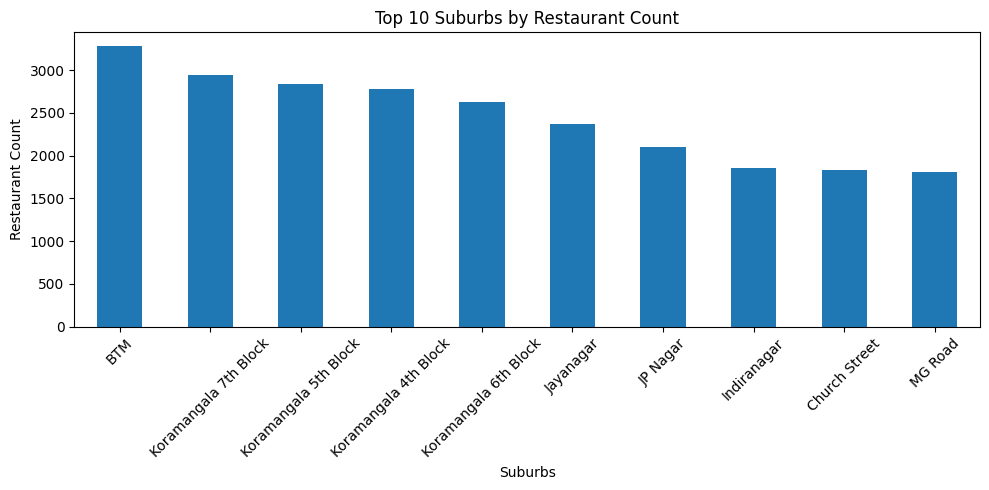

In [17]:
top_suburbs = suburb_count.sort_values(
    ascending=False
).head(10)

top_suburbs.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 Suburbs by Restaurant Count")
plt.xlabel("Suburbs")
plt.ylabel("Restaurant Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

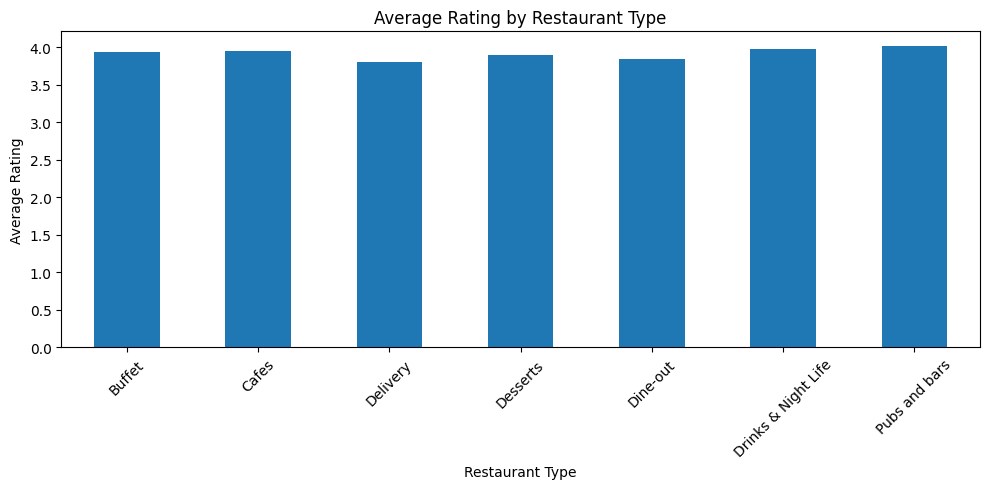

In [18]:
rating_type = df.groupby("Restaurant Type")["Avg Rating"].mean()

rating_type.plot(kind="bar", figsize=(10,5))

plt.title("Average Rating by Restaurant Type")
plt.xlabel("Restaurant Type")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

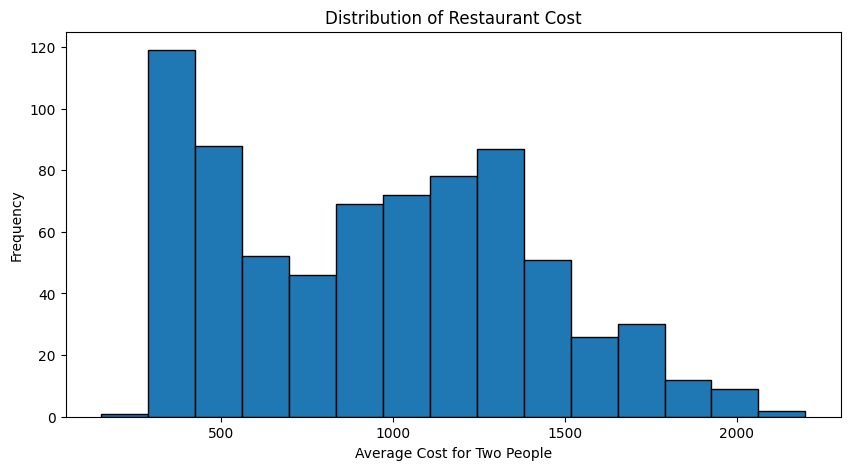

In [19]:
plt.figure(figsize=(10,5))

plt.hist(df["Avg Approx Cost (For Two People)"],
         bins=15, edgecolor="black")

plt.title("Distribution of Restaurant Cost")
plt.xlabel("Average Cost for Two People")
plt.ylabel("Frequency")
plt.show()

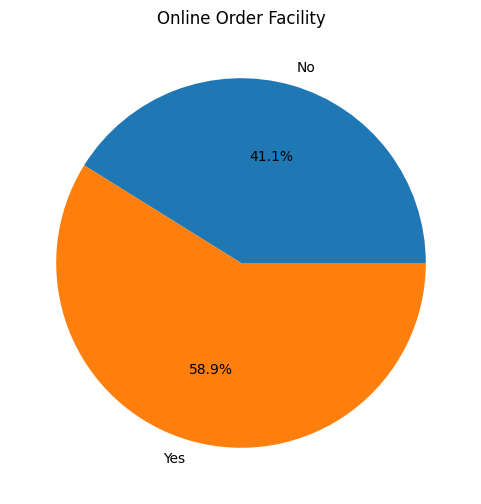

In [20]:
online_count = df.groupby("Online Order Facility")["Restaurant Count"].sum()

online_count.plot(kind="pie", autopct="%1.1f%%",
                  figsize=(6,6))

plt.title("Online Order Facility")
plt.ylabel("")
plt.show()

In [21]:
df.to_csv("zomato_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
